# Hwang et al. 2022 — Pancreatic Ductal Adenocarcinoma (snRNA-seq, TP10K)
## 01 · Preprocessing
Load malignant nuclei from the 3 group matrices, threshold under-populated samples, select overdispersed genes, PCA, Harmony integrate on `sample` (theta swept), embed, remove detached islands, annotate compartments, and settle **Gate 1** on the regenerated embedding.

In [1]:
import os, sys, glob, warnings
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, anndata as ad
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/mesencontext/claude/<Category>/<Dataset>
name = os.path.basename(os.getcwd())                    # 'Hwang2022_Pancreas-2'
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # 'Pancreas'
pth  = os.path.join(*([os.pardir]*4))                   # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata
# raw folder is the dataset name minus the run '-2' suffix, prefixed 'Data_'
base = name.split('-')[0]                               # 'Hwang2022_Pancreas'
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + base)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Hwang2022_Pancreas-2 | category: Pancreas


**Load & select malignant nuclei.** Hwang 2022 ships three group matrices (TP10K-normalized snRNA-seq); the loader walks each leaf directory as `merge.py` does, and we concatenate.

In [4]:
leaves = sorted(dp for dp,sub,fs in os.walk(pth_in)
                if len(sub)==0 and any(f.endswith('.mtx') for f in fs))
parts = {}
for l in leaves:
    a = load_CCCA_adata(l, verbose=False)
    a = a[a.obs['celltype'] == 'Malignant'].copy()
    parts[os.path.basename(l)] = a
adata = ad.concat(parts, join='outer', merge='same', label='group')
adata.obs_names_make_unique()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p of TP10K)' % float(adata.X.max()))

malignant: (64538, 22164) | samples: 43
expression: X max 5.88 (log1p of TP10K)


**Sample threshold.** Sort per-sample malignant counts, find the largest multiplicative gap, and place the threshold at the geometric mean across it (floored at 100 cells).

In [6]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float); ratios = vals[:-1]/vals[1:]; gap = int(np.argmax(ratios))
FLOOR = 100
thresh = FLOOR if gap==0 else int(np.sqrt(vals[gap]*vals[gap+1]))
if thresh < FLOOR: thresh = FLOOR
print('sorted per-sample counts:', n.values)
print(f'largest gap {int(vals[gap])}->{int(vals[gap+1])} (ratio {ratios[gap]:.2f}); threshold = {thresh}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples -> {adata.shape[0]} cells (min kept = {int(adata.obs.groupby("sample",observed=True).size().min())})')

sorted per-sample counts: [7167 5790 4865 4766 4349 3808 3652 3557 3284 3271 3114 2875 1963 1536
 1501 1426 1304 1068 1019  817  609  485  478  446  342  182  175  155
  100   85   65   46   44   39   35   33   32   24    9    9    6    4
    3]
largest gap 24->9 (ratio 2.67); threshold = 100
kept 29/43 samples -> 64104 cells (min kept = 100)


**Genes, overdispersion, PCA.** No `sc.pp.scale` (absent from the reference protocol).

In [8]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()), '| genes:', adata.shape[1])
sc.pp.pca(adata, n_comps=50)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 1645 over-dispersed features (0:00:06) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 1645 | genes: 19444


**Harmony integration — theta sweep (Gate 1 evidence).** iLISI is a per-neighbourhood metric (effective # of samples among each cell's 90 neighbours); the same-sample neighbour fraction is its complement. Mixing plateaus by theta=5; we take theta=10 (strongest integration without collapse, matching the Steele2020 PDAC precedent) and n_pcs=20 (robust range 20-40; 20 matches the Kürten/Steele scale).

In [10]:
def _ilisi(rep, labels, k=90):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes; L = codes[idx]; out = np.empty(len(rep))
    for i in range(len(rep)):
        _,ct = np.unique(L[i], return_counts=True); p = ct/k; out[i] = 1.0/np.sum(p**2)
    return out
def _same(rep):
    idx = NearestNeighbors(n_neighbors=31).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    s = adata.obs['sample'].values
    return float(np.mean([(s[idx[i]]==s[i]).mean() for i in range(len(s))]))
samp = adata.obs['sample'].values; nsamp = adata.obs['sample'].nunique()
print(f'pre-Harmony : iLISI(med)={np.median(_ilisi(adata.obsm["X_pca"][:,:20],samp)):.2f}/{nsamp}  same-sample-frac={_same(adata.obsm["X_pca"][:,:20]):.3f}')
for th in [2, 5, 10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=20, random_state=SEED)
    print(f'theta={th:<2d}: iLISI(med)={np.median(_ilisi(adata.obsm["X_pca_harmony"][:,:20],samp)):.2f}  same-sample-frac={_same(adata.obsm["X_pca_harmony"][:,:20]):.3f}')
# theta=10 rep is the last computed; embed on it
THETA, NPC = 10, 20
print('selected theta =', THETA, '| n_pcs =', NPC)
sc.pp.neighbors(adata, n_pcs=NPC, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

pre-Harmony : iLISI(med)=1.00/29  same-sample-frac=0.967
2026-08-07 01:25:49,846 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-07 01:25:55,536 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-07 01:25:56,067 - harmonypy - INFO - Iteration 1 of 20
2026-08-07 01:26:33,829 - harmonypy - INFO - Iteration 2 of 20
2026-08-07 01:27:10,115 - harmonypy - INFO - Iteration 3 of 20
2026-08-07 01:27:47,832 - harmonypy - INFO - Iteration 4 of 20
2026-08-07 01:28:21,658 - harmonypy - INFO - Iteration 5 of 20
2026-08-07 01:28:43,692 - harmonypy - INFO - Iteration 6 of 20
2026-08-07 01:29:06,721 - harmonypy - INFO - Iteration 7 of 20
2026-08-07 01:29:26,014 - harmonypy - INFO - Iteration 8 of 20
2026-08-07 01:29:44,369 - harmonypy - INFO - Iteration 9 of 20
2026-08-07 01:30:02,175 - harmonypy - INFO - Iteration 10 of 20
2026-08-07 01:30:17,101 - harmonypy - INFO - Iteration 11 of 20
2026-08-07 01:30:32,171 - harmonypy - INFO - Iteration 12 of 20
202

**Remove detached islands.** UMAP radius graph at 6x the median nearest-neighbour distance; keep the largest connected component (strips only disconnected specks).

In [12]:
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('removed', int((lab!=main).sum()), 'cells in', ncomp-1, 'detached islands ->', int((lab==main).sum()), 'kept')
adata = adata[lab==main].copy()
sc.pp.neighbors(adata, n_pcs=NPC, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)

removed 98 cells in 6 detached islands -> 64006 kept


**Compartment annotation — data markers + publication programs.** Leiden (res 0.15) resolves the two density poles of the continuous manifold. We score Moffitt et al. 2015 classical/basal programs (data-derived) and cross-check Hwang et al. 2022 malignant meta-programs (`mp_top`). Cycling fraction per lobe rules out a proliferation confound.

In [14]:
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].astype(str).isin(['G1/S','G2/M','Intermediate'])
print('lobe sizes:', adata.obs['lobe'].value_counts().to_dict())
print('cycling fraction per lobe:', adata.obs.groupby('lobe',observed=True)['cycling'].mean().round(3).to_dict())
classical = ['GATA6','TFF1','TFF2','LGALS4','CEACAM6','CEACAM5','TSPAN8','ST6GALNAC1','AGR2','CLRN3',
             'LYZ','MYO1A','CDH17','VSIG2','BTNL8','FAM3D','SPINK4']
basal = ['KRT17','KRT15','KRT6A','KRT6C','KRT5','KRT7','KRT14','TP63','S100A2','SPRR3','SPRR1B','LY6D',
         'SCEL','FAM83A','SLC2A1','CST6','DHRS9','LEMD1','GPR87']
for nm,gs in [('classical',classical),('basal',basal)]:
    g = [x for x in gs if x in adata.var_names]
    sc.tl.score_genes(adata, g, score_name=nm+'_score', random_state=SEED)
    print(f'{nm}: {len(g)}/{len(gs)} genes | per-lobe', adata.obs.groupby('lobe',observed=True)[nm+'_score'].mean().round(3).to_dict())
cl = adata.obs.groupby('lobe',observed=True)['classical_score'].mean()
cls_lobe = cl.idxmax()
lab_map = {l: ('Classical-like' if l==cls_lobe else 'Basal-like') for l in adata.obs['lobe'].cat.categories}
adata.obs['celltype'] = adata.obs['lobe'].map(lab_map).astype('category')
if 'mp_top' in adata.obs:
    print('Hwang mp_top top programs per compartment:')
    ct = pd.crosstab(adata.obs['celltype'], adata.obs['mp_top'].astype(str), normalize='index')
    for comp in ct.index:
        print(' ', comp, dict(ct.loc[comp].drop('nan',errors='ignore').sort_values(ascending=False).head(3).round(2)))
print('compartments:', adata.obs['celltype'].value_counts().to_dict())

lobe sizes: {'1': 29245, '0': 25550, '2': 9211}
cycling fraction per lobe: {'0': 0.069, '1': 0.06, '2': 0.065}
classical: 16/17 genes | per-lobe {'0': 0.015, '1': -0.015, '2': 0.044}
basal: 19/19 genes | per-lobe {'0': 0.015, '1': 0.023, '2': 0.099}
Hwang mp_top top programs per compartment:
  Basal-like {'MP41 (Unassigned)': np.float64(0.14), 'EMT II': np.float64(0.04), 'Chromatin': np.float64(0.04)}
  Classical-like {'EMT III': np.float64(0.17), 'MP41 (Unassigned)': np.float64(0.07), 'EMT II': np.float64(0.05)}
compartments: {'Basal-like': 54795, 'Classical-like': 9211}


**Gate 1 — mixing + continuity on the regenerated embedding.**

In [16]:
il_pre  = np.median(_ilisi(adata.obsm['X_pca'][:,:20], adata.obs['sample'].values))
il_post = np.median(_ilisi(adata.obsm['X_pca_harmony'][:,:20], adata.obs['sample'].values))
xy = adata.obsm['X_umap']; c0 = xy - xy.mean(0); _,s,_ = np.linalg.svd(c0, full_matrices=False)
print(f'iLISI median: pre-Harmony {il_pre:.2f} -> post-Harmony(theta=10) {il_post:.2f} of {adata.obs["sample"].nunique()} samples')
print(f'UMAP principal-axis ratio (major/minor) = {s[0]/s[1]:.2f} (near 1 = compact continuous mass, not a strip of islands)')
print('one connected component after island removal; both compartments contain multiple samples.')
print('GATE 1 = GO: samples intermix per-neighbourhood on one continuous, proliferation-independent manifold.')

iLISI median: pre-Harmony 1.00 -> post-Harmony(theta=10) 9.31 of 29 samples
UMAP principal-axis ratio (major/minor) = 1.37 (near 1 = compact continuous mass, not a strip of islands)
one connected component after island removal; both compartments contain multiple samples.
GATE 1 = GO: samples intermix per-neighbourhood on one continuous, proliferation-independent manifold.


In [17]:
# persist obs dtypes cleanly, save processed.h5ad
for col in adata.obs.columns:
    v = adata.obs[col]
    if v.dtype == object:
        conv = pd.to_numeric(v, errors='coerce')
        adata.obs[col] = conv if (v.notna().sum()>0 and conv.notna().sum()>=0.9*v.notna().sum()) else v.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (64006, 19444)


**Figure — `samples.pdf`.** House `(3.5,1.5)` strip, coloured by sample; intermixing across the manifold is the Gate-1 integration evidence. Shown on the house linear orientation (built in 02, computed here as a rigid rotation so all panels share one orientation).

saved samples.pdf | cells: 64006


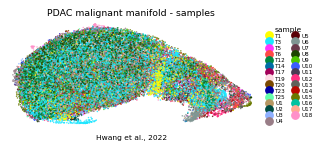

In [19]:
import scipy.sparse as sp
# house orientation: rigid rotation of X_umap onto its principal axis (distances preserved, NOT a re-embed)
xy = adata.obsm['X_umap']; c0 = xy - xy.mean(0)
_,_,vt = np.linalg.svd(c0, full_matrices=False); th = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[np.cos(-th),-np.sin(-th)],[np.sin(-th),np.cos(-th)]]); xyr = c0 @ Rm.T
# orient Gast/pSom-high (developmental origin) pole to the left using a quick module score
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,l in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=l, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0]); A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
origin = S[:,0] + S[:,1] - S[:,2]; w = origin - origin.min()
if np.average(xyr[:,0], weights=w) > 0: xyr[:,0] = -xyr[:,0]
adata.obsm['X_umap_lin'] = xyr
adata.write(os.path.join(pth_out, 'processed.h5ad'))
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']; xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=6, alpha=.8, frameon=False, show=False, ax=ax)
h,l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=2, frameon=False, loc='center left', bbox_to_anchor=(1.02,.5),
          handletextpad=.2, labelspacing=.2, columnspacing=.5, fontsize=4.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title('PDAC malignant manifold - samples', size=7.5)
ax.text(.5,-.12,'Hwang et al., 2022', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', plot.shape[0])